# Monte Carlo Integration

**Seong Cho** · ACME Volume 1, Lab 11

**Lab objective:** implement Monte Carlo integration, an integration strategy with relatively slow convergence that does extremely well in high-dimensional settings, and apply it to a classic problem in statistics.

<sub>Lab specification from the *Volume 1* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
from scipy import linalg as la
from scipy import stats
import matplotlib.pyplot as plt

Many important integrals cannot be evaluated symbolically because the integrand has no antiderivative. Traditional numerical integration techniques like Newton-Cotes formulas and Gaussian quadrature usually work well for one-dimensional integrals, but rapidly become inefficient in higher dimensions.

## Volume Estimation

Since the area of a circle of radius $r$ is $A = \pi r^2$, one way to numerically estimate $\pi$ is to compute the area of the unit circle. Randomly choose points in a domain that encompasses the unit circle: the percentage of points that land within the circle approximates the percentage of the domain's area that the circle occupies, and multiplying this percentage by the total area of the domain estimates the area of the circle.

For the unit circle, consider the square domain $\Omega = [-1, 1] \times [-1, 1]$. The following code samples 2000 uniformly distributed random points in $\Omega$, determines what percentage of them are within the unit circle, then multiplies that percentage by 4 (the area of $\Omega$) to estimate $\pi$.

In [2]:
np.random.seed(0)

# Get 2000 random points in the 2-D domain [-1,1]x[-1,1].
points = np.random.uniform(-1, 1, (2,2000))

# Determine how many points are within the circle.
lengths = la.norm(points, axis=0)
num_within = np.count_nonzero(lengths < 1)

# Estimate the circle's area.
4 * (num_within / 2000)

np.float64(3.142)

The spec's run gave $\pi \approx 3.198$, which isn't perfect but differs from the true value of $\pi$ by only about $0.0564$. On average, increasing the number of sample points decreases the estimate error. Figure 11.1 of the spec shows estimates from 500, 2000, and 8000 points (3.088, 3.198, and 3.167 there); the same experiment:

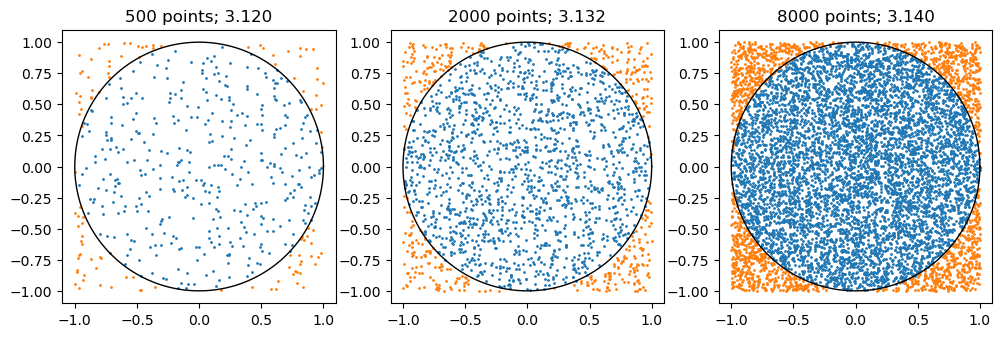

In [3]:
np.random.seed(1)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
t = np.linspace(0, 2*np.pi, 200)
for ax, N in zip(axes, [500, 2000, 8000]):
    pts = np.random.uniform(-1, 1, (2, N))
    inside = la.norm(pts, axis=0) < 1
    ax.plot(pts[0, inside], pts[1, inside], 'C0.', ms=2)
    ax.plot(pts[0, ~inside], pts[1, ~inside], 'C1.', ms=2)
    ax.plot(np.cos(t), np.sin(t), 'k', lw=1)
    ax.set_aspect("equal")
    ax.set_title(f"{N} points; {4*np.mean(inside):.3f}")
plt.show()

## Problem 1: Volume of the unit ball

> **Problem 1.** The $n$-dimensional open unit ball is the set $U_n = \{\mathbf{x} \in \mathbb{R}^n \mid \|\mathbf{x}\|_2 < 1\}$. Write a function that accepts an integer $n$ and a keyword argument $N$ defaulting to $10^4$. Estimate the volume of $U_n$ by drawing $N$ points over the $n$-dimensional domain $[-1, 1] \times [-1, 1] \times \cdots \times [-1, 1]$.
>
> (Hint: the volume of $[-1, 1] \times [-1, 1] \times \cdots \times [-1, 1]$ is $2^n$.)
>
> When $n = 2$, this is the same experiment outlined above so your function should return an approximation of $\pi$. The volume of the $U_3$ is $\frac{4}{3}\pi \approx 4.18879$, and the volume of $U_4$ is $\frac{\pi^2}{2} \approx 4.9348$. Try increasing the number of sample points $N$ to see if your estimates improve.

In [4]:
def ball_volume(n, N=10000):
    """Estimate the volume of the n-dimensional unit ball.

    Parameters:
        n (int): The dimension of the ball. n=2 corresponds to the unit circle,
            n=3 corresponds to the unit sphere, and so on.
        N (int): The number of random points to sample.

    Returns:
        (float): An estimate for the volume of the n-dimensional unit ball.
    """
    # Volume of the n-dimentional hypercube with length 2
    V_s = 2**n
    # Sample points
    points = np.random.uniform(-1, 1, (n,N))
    # Determine the number of points within the circle
    lengths = la.norm(points, axis=0)
    num_within = np.count_nonzero(lengths < 1)
    # Estimate the circle's area
    return V_s * (num_within / N)

The exact volume is $\operatorname{vol}(U_n) = \dfrac{\pi^{n/2}}{\Gamma(n/2 + 1)}$. The estimates approach it as $N$ grows:

In [5]:
from scipy.special import gamma

np.random.seed(2)
print(f"{'n':>2}{'exact':>10}{'N=10^3':>10}{'N=10^4':>10}{'N=10^5':>10}{'N=10^6':>10}")
for n in [2, 3, 4, 5]:
    exact = np.pi**(n/2) / gamma(n/2 + 1)
    est = [ball_volume(n, N=10**k) for k in range(3, 7)]
    assert abs(est[-1] - exact) / exact < 0.01
    print(f"{n:2d}{exact:10.5f}" + "".join(f"{e:10.4f}" for e in est))

 n     exact    N=10^3    N=10^4    N=10^5    N=10^6
 2   3.14159    3.1240    3.1272    3.1306    3.1393
 3   4.18879    4.0720    4.1696    4.1807    4.1977
 4   4.93480    4.5600    4.9936    4.9723    4.9209
 5   5.26379    5.1840    5.2448    5.2794    5.2495


## Integral Estimation

The strategy for estimating $\pi$ can be formulated as an integral problem. Define $f : \mathbb{R}^2 \to \mathbb{R}$ by

$$f(\mathbf{x}) = \begin{cases} 1 & \text{if } \|\mathbf{x}\|_2 < 1 \text{ (}\mathbf{x}\text{ is within the unit circle)} \\ 0 & \text{otherwise,} \end{cases}$$

and let $\Omega = [-1, 1] \times [-1, 1]$ as before. Then

$$\int_{-1}^1\int_{-1}^1 f(x, y)\,dx\,dy = \int_\Omega f(\mathbf{x})\,dV = \pi.$$

To estimate the integral, choose $N$ random points $\{\mathbf{x}_i\}_{i=1}^N$ in $\Omega$. Since $f$ indicates whether or not a point lies within the unit circle, the number of random points in the circle is the sum of the $f(\mathbf{x}_i)$. The average of these values, multiplied by the volume $V(\Omega)$, is the desired estimate:

$$\int_\Omega f(\mathbf{x})\,dV \approx V(\Omega)\frac{1}{N}\sum_{i=1}^N f(\mathbf{x}_i). \tag{11.1}$$

This remarkably simple equation can be used to estimate the integral of any integrable function $f : \mathbb{R}^n \to \mathbb{R}$ over any domain $\Omega \subset \mathbb{R}^n$ and is called the *general formula for Monte Carlo integration*.

The intuition is that $\frac{1}{N}\sum_{i=1}^N f(\mathbf{x}_i)$ approximates the average value of $f$ on $\Omega$, and multiplying the approximate average value by the volume of $\Omega$ yields the approximate integral of $f$ over $\Omega$. In one dimension, the Average Value Theorem states that the average value of $f$ over $[a, b]$ is $f_{\text{avg}} = \frac{1}{b - a}\int_a^b f(x)\,dx$. Using $f_{\text{avg}} \approx \frac{1}{N}\sum_{i=1}^N f(x_i)$,

$$\int_a^b f(x)\,dx = (b - a)f_{\text{avg}} \approx V(\Omega)\frac{1}{N}\sum_{i=1}^N f(x_i), \tag{11.2}$$

which is (11.1) in one dimension, with $\Omega = [a, b]$ and $V(\Omega) = b - a$.

## Problem 2: Monte Carlo integration in 1-D

> **Problem 2.** Write a function that accepts a function $f : \mathbb{R} \to \mathbb{R}$, bounds of integration $a$ and $b$, and an integer $N$ defaulting to $10^4$. Use `np.random.uniform()` to sample $N$ points over the interval $[a, b]$, then use (11.2) to estimate the integral
>
> $$\int_a^b f(x)\,dx.$$
>
> Test your function on the following integrals, or on other integrals that you can check by hand.
>
> $$\int_{-4}^2 x^2\,dx = 24 \qquad \int_{-2\pi}^{2\pi} \sin(x)\,dx = 0 \qquad \int_1^{10} \frac{1}{x}\,dx = \log(10) \approx 2.30259$$
>
> $$\int_1^5 \left|\sin(10x)\cos(10x) + \sqrt{x}\sin(3x)\right|\,dx \approx 4.502$$

In [6]:
def mc_integrate1d(f, a, b, N=10000):
    """Approximate the integral of f on the interval [a,b].

    Parameters:
        f (function): the function to integrate. Accepts and returns scalars.
        a (float): the lower bound of interval of integration.
        b (float): the upper bound of interval of integration.
        N (int): The number of random points to sample.

    Returns:
        (float): An approximation of the integral of f over [a,b].

    Example:
        >>> f = lambda x: x**2
        >>> mc_integrate1d(f, -4, 2)    # Integrate from -4 to 2.
        23.734810301138324              # The true value is 24.
    """
    # Length of the interval
    V_o = (b-a)
    # Sample points
    points = np.random.uniform(a, b, N)
    # Estimate the integral (11.2)
    return V_o * sum(f(x) for x in points) / N

The test integrals, with SciPy's `quad()` as the reference for the last one. The tolerance is four standard errors of the estimate, $4(b - a)\,\operatorname{std}(f)/\sqrt{N}$.

In [7]:
from scipy.integrate import quad

tests = [(lambda x: x**2, -4, 2, 24),
         (lambda x: np.sin(x), -2*np.pi, 2*np.pi, 0),
         (lambda x: 1/x, 1, 10, np.log(10)),
         (lambda x: abs(np.sin(10*x)*np.cos(10*x) + np.sqrt(x)*np.sin(3*x)), 1, 5, None)]

np.random.seed(3)
for f, a, b, exact in tests:
    if exact is None:
        exact = quad(f, a, b, limit=200)[0]
    est = mc_integrate1d(f, a, b)
    se = (b - a) * np.std(f(np.random.uniform(a, b, 10**5))) / np.sqrt(10000)
    assert abs(est - exact) < 4*se
    print(f"estimate {est:9.5f}   exact {exact:9.5f}   standard error {se:.3f}")

estimate  24.15494   exact  24.00000   standard error 0.262
estimate   0.09753   exact   0.00000   standard error 0.089
estimate   2.31688   exact   2.30259   standard error 0.017
estimate   4.50362   exact   4.50201   standard error 0.027


> **Achtung!** Be careful not to use Monte Carlo integration to estimate integrals that do not converge. For example, since $1/x$ approaches $\infty$ as $x$ approaches 0 from the right, the integral
>
> $$\int_0^1 \frac{1}{x}\,dx$$
>
> does not converge. Even so, attempts at Monte Carlo integration still return a finite value. Use various numbers of sample points to see whether or not the integral estimate is converging.

In [8]:
np.random.seed(4)
for N in [5000, 7500, 10000]:
    print(np.mean(1. / np.random.uniform(0, 1, N)), end='\t')        # No convergence.

8.616205215045463	8.830580786692698	10.867601985021665	

(The spec's run printed `11.8451683722 25.5814419888 7.64364735049`.) With much larger samples the estimates still don't settle: the mean of $1/U$ for uniform $U$ is infinite, so the estimates keep changing as $N$ grows instead of converging.

In [9]:
np.random.seed(8)
for N in [10**4, 10**5, 10**6, 10**7]:
    print(f"N = {N:>8}: {np.mean(1. / np.random.uniform(0, 1, N)):.4f}")

N =    10000: 10.1843
N =   100000: 13.5987
N =  1000000: 17.8187
N = 10000000: 17.6330


## Integration in Higher Dimensions

Implementing (11.1) for $f : \mathbb{R}^n \to \mathbb{R}$ with $n > 1$ introduces a few tricky details, but the procedure is the same. Consider only the case where $\Omega \subset \mathbb{R}^n$ is an $n$-dimensional box $[a_1, b_1] \times [a_2, b_2] \times \cdots \times [a_n, b_n]$.

1. If $n = 1$ then $\Omega$ is a line, so $V(\Omega) = b_1 - a_1$. If $n = 2$ then $\Omega$ is a rectangle, and $V(\Omega) = (b_1 - a_1)(b_2 - a_2)$. The volume of a higher-dimensional box is also the product of the side lengths:
$$V(\Omega) = \prod_{i=1}^n (b_i - a_i) \tag{11.3}$$
2. It is easy to sample uniformly over an interval $[a, b]$ with `np.random.uniform()`, or even over the cube $[a, b] \times \cdots \times [a, b]$ (as in Problem 1). But if $a_i \neq a_j$ or $b_i \neq b_j$ for any $i \neq j$, the samples need to be constructed differently. The interval $[0, 1]$ can be transformed to $[a, b]$ by scaling it to the same length, then shifting it:
$$[0, 1] \xrightarrow{\text{scale by } b - a} [0, b - a] \xrightarrow{\text{shift by } a} [a, b].$$
So sample uniformly from the box $[0, 1] \times \cdots \times [0, 1]$, multiply the $i$th component of each sample by $b_i - a_i$, then add $a_i$ to that component:
$$[0, 1] \times \cdots \times [0, 1] \xrightarrow{\text{scale}} [0, b_1 - a_1] \times \cdots \times [0, b_n - a_n] \xrightarrow{\text{shift}} [a_1, b_1] \times \cdots \times [a_n, b_n] \tag{11.4}$$

## Problem 3: Monte Carlo integration in n-D

> **Problem 3.** Write a function that accepts a function $f : \mathbb{R}^n \to \mathbb{R}$, a list of lower bounds $[a_1, a_2, \ldots, a_n]$, a list of upper bounds $[b_1, b_2, \ldots, b_n]$, and an integer $N$ defaulting to $10^4$. Use (11.1), (11.3), and (11.4) with $N$ sample points to estimate the integral
>
> $$\int_\Omega f(\mathbf{x})\,dV,$$
>
> where $\Omega = [a_1, b_1] \times [a_2, b_2] \times \cdots \times [a_n, b_n]$.
>
> (Hint: use a list comprehension to calculate all of the $f(\mathbf{x}_i)$ quickly.)
>
> Test your function on the following integrals.
>
> $$\int_0^1\int_0^1 x^2 + y^2\,dx\,dy = \frac{2}{3} \qquad \int_{-2}^1\int_1^3 3x - 4y + y^2\,dx\,dy = 54$$
>
> $$\int_{-4}^4\int_{-3}^3\int_{-2}^2\int_{-1}^1 x + y - wz^2\,dx\,dy\,dz\,dw = 0$$
>
> Note carefully how the order of integration defines the domain. In the last example, the $x$-$y$-$z$-$w$ domain is $[-1, 1] \times [-2, 2] \times [-3, 3] \times [-4, 4]$, so the lower and upper bounds passed to your function should be $[-1, -2, -3, -4]$ and $[1, 2, 3, 4]$, respectively.

In [10]:
def mc_integrate(f, mins, maxs, N=10000):
    """Approximate the integral of f over the box defined by mins and maxs.

    Parameters:
        f (function): The function to integrate. Accepts and returns
            1-D NumPy arrays of length n.
        mins (list): the lower bounds of integration.
        maxs (list): the upper bounds of integration.
        N (int): The number of random points to sample.

    Returns:
        (float): An approximation of the integral of f over the domain.

    Example:
        # Define f(x,y) = 3x - 4y + y^2. Inputs are grouped into an array.
        >>> f = lambda x: 3*x[0] - 4*x[1] + x[1]**2

        # Integrate over the box [1,3]x[-2,1].
        >>> mc_integrate(f, [1, -2], [3, 1])
        53.562651072181225              # The true value is 54.
    """
    delta = np.array(maxs) - np.array(mins)
    # Volume of the region (11.3)
    V_o = np.prod(delta)
    # Number of dimensions
    n = len(mins)
    # Sample points from [0,1]
    pts = np.random.uniform(0, 1, (N, n))
    # Scale the points (11.4)
    pts *= delta
    pts += mins
    # Estimate the integral (11.2)
    return V_o * sum(f(x) for x in pts) / N

The spec's three test integrals, with the same four-standard-error tolerance as before:

In [11]:
tests = [(lambda x: x[0]**2 + x[1]**2, [0, 0], [1, 1], 2/3),
         (lambda x: 3*x[0] - 4*x[1] + x[1]**2, [1, -2], [3, 1], 54),
         (lambda x: x[0] + x[1] - x[3]*(x[2]**2), [-1, -2, -3, -4], [1, 2, 3, 4], 0)]

np.random.seed(5)
for f, mins, maxs, exact in tests:
    est = mc_integrate(f, mins, maxs)
    V = np.prod(np.subtract(maxs, mins))
    sample = np.random.uniform(mins, maxs, (10**5, len(mins)))
    se = V * np.std([f(x) for x in sample]) / np.sqrt(10000)
    assert abs(est - exact) < 4*se
    print(f"estimate {est:9.4f}   exact {exact:9.4f}   standard error {se:.3f}")

estimate    0.6754   exact    0.6667   standard error 0.004
estimate   53.8383   exact   54.0000   standard error 0.284


estimate -100.0812   exact    0.0000   standard error 35.893


## Convergence

Monte Carlo integration has some obvious pros and cons. On the one hand, it is difficult to get highly precise estimates. In fact, the error of the Monte Carlo method is proportional to $1/\sqrt{N}$, where $N$ is the number of points used in the estimation. This means that dividing the error by 10 requires using 100 times more sample points.

On the other hand, the convergence rate is independent of the number of dimensions of the problem. That is, the error converges at the same rate whether integrating a 2-dimensional function or a 20-dimensional function. This gives Monte Carlo integration a huge advantage over other methods, and makes it especially useful for estimating integrals in high dimensions where other methods become computationally infeasible.

## Problem 4: Convergence for the multivariate normal

> **Problem 4.** The probability density function of the joint distribution of $n$ independent normal random variables, each with mean 0 and variance 1, is the function $f : \mathbb{R}^n \to \mathbb{R}$ defined by
>
> $$f(\mathbf{x}) = \frac{1}{(2\pi)^{n/2}}e^{-\frac{\mathbf{x}^T\mathbf{x}}{2}}.$$
>
> Though this is a critical distribution in statistics, $f$ does not have a symbolic antiderivative. Integrate $f$ several times to study the convergence properties of Monte Carlo integration.
>
> 1. Let $n = 4$ and $\Omega = [-\frac{3}{2}, \frac{3}{4}] \times [0, 1] \times [0, \frac{1}{2}] \times [0, 1] \subset \mathbb{R}^4$. Define $f$ and $\Omega$ so that you can integrate $f$ over $\Omega$ using your function from Problem 3.
> 2. Use `scipy.stats.mvn.mvnun()` to get the "exact" value of $F = \int_\Omega f(\mathbf{x})\,dV$. As an example, the following code computes the integral over $[-1, 1] \times [-1, 3] \times [-2, 1] \subset \mathbb{R}^3$.
>
>    ```python
>    >>> from scipy import stats
>
>    # Define the bounds of integration.
>    >>> mins = np.array([-1, -1, -2])
>    >>> maxs = np.array([ 1, 3, 1])
>
>    # The distribution has mean 0 and covariance I (the nxn identity).
>    >>> means, cov = np.zeros(3), np.eye(3)
>
>    # Compute the integral with SciPy.
>    >>> stats.mvn.mvnun(mins, maxs, means, cov)[0]
>    0.4694277116055261
>    ```
>
> 3. Use `np.logspace()` to get 20 integer values of $N$ that are roughly logarithmically spaced from $10^1$ to $10^5$. For each value of $N$, use your function from Problem 3 to compute 25 estimates of the integral with $N$ samples, and average these estimates to obtain $\tilde{F}(N)$. Compute the relative error $\frac{|F - \tilde{F}(N)|}{|F|}$ for each value of $N$.
> 4. Plot the relative error against the sample size $N$ on a log-log scale. Also plot the line $1/\sqrt{N}$ for comparison. Your results should be similar to Figure 11.2.
>
> *[Figure 11.2 shows the relative error falling, noisily, from about $10^{-2}$ at $N = 10^1$ to between $10^{-5}$ and $10^{-4}$ at $N = 10^5$, below and roughly parallel to the line $1/\sqrt{N}$.]*

`scipy.stats.mvn.mvnun()` no longer exists in current SciPy (1.16 here): the `scipy.stats.mvn` module is deprecated and `mvnun` was removed. The same integral is now computed by `stats.multivariate_normal.cdf()`, whose `lower_limit` argument (added in SciPy 1.10) gives the integral over a box:

In [12]:
# Define the bounds of integration.
mins = np.array([-1, -1, -2])
maxs = np.array([ 1, 3, 1])

# The distribution has mean 0 and covariance I (the nxn identity).
means, cov = np.zeros(3), np.eye(3)

# Compute the integral with SciPy (the replacement for mvnun).
stats.multivariate_normal.cdf(maxs, mean=means, cov=cov, lower_limit=mins)

np.float64(0.46942771160552604)

In [13]:
def prob4():
    """Let n=4 and Omega = [-3/2,3/4]x[0,1]x[0,1/2]x[0,1].
    - Define the joint distribution f of n standard normal random variables.
    - Use SciPy to integrate f over Omega.
    - Get 20 integer values of N that are roughly logarithmically spaced from
        10**1 to 10**5. For each value of N, use mc_integrate() to compute 25
        estimates of the integral of f over Omega with N samples, and average
        the estimates together. Compute the relative error of each average.
    - Plot the relative error against the sample size N on a log-log scale.
        Also plot the line 1 / sqrt(N) for comparison.
    """
    # Define the function and its mins/maxs
    f = lambda x: (1/(2*np.pi)**(len(x)/2))*np.exp(-np.dot(x,x)/2)
    mins = [-3/2, 0, 0, 0]
    maxs = [3/4, 1, 1/2, 1]
    # Calculate the exact value of f using scipy
    means, cov = np.zeros(4), np.eye(4)
    # Changed: stats.mvn.mvnun(mins, maxs, means, cov)[0] was removed from SciPy;
    # multivariate_normal.cdf() with lower_limit computes the same box integral.
    F = stats.multivariate_normal.cdf(maxs, mean=means, cov=cov, lower_limit=mins)
    # Record the relative error for varying sample sizes
    domain = np.logspace(1, 5, 20)
    error = []
    for N in domain:
        Fm = sum(mc_integrate(f, mins, maxs, N=int(N)) for i in range(25))/25
        error.append(abs((F-Fm)/F))
    # Plot the result
    plt.loglog(domain, error, label="Relative Error")
    plt.loglog(domain, 1/np.sqrt(domain), label=r'1/sqrt(N)')
    plt.legend()
    plt.show()

Because the covariance is the identity, $F$ factors into a product of one-dimensional normal probabilities, $F = \prod_{i=1}^4 \left(\Phi(b_i) - \Phi(a_i)\right)$, which confirms the "exact" value used in `prob4()`:

In [14]:
mins4, maxs4 = np.array([-3/2, 0, 0, 0]), np.array([3/4, 1, 1/2, 1])
F = stats.multivariate_normal.cdf(maxs4, mean=np.zeros(4), cov=np.eye(4), lower_limit=mins4)
assert np.isclose(F, np.prod(stats.norm.cdf(maxs4) - stats.norm.cdf(mins4)))
print(F)

0.01576240484486122


The full experiment at the spec's sizes (20 values of $N$ up to $10^5$, 25 estimates each):

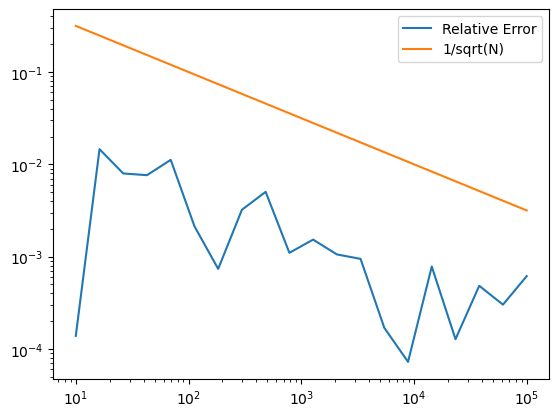

In [15]:
np.random.seed(6)
prob4()

## The script's `main()`

The original `.py` file ran each problem from the command line through `main()` (as `python montecarlo_integration.py prob1`, and so on, which first called `plt.ion()`). The command-line hook isn't needed in a notebook, so only `main()` is kept; Problem 4 already ran above.

In [16]:
def main(prob):
    if prob == "prob1":
        print(ball_volume(2))
        print(ball_volume(3))
        print(ball_volume(4))

    if prob == "prob2":
        f1 = lambda x: x**2
        f2 = lambda x: np.sin(x)
        f3 = lambda x: 1/x
        f4 = lambda x: abs(np.sin(10*x)*np.cos(10*x) + np.sqrt(x)*np.sin(3*x))
        print(mc_integrate1d(f1, -4, 2))
        print(mc_integrate1d(f2, -2*np.pi, 2*np.pi))
        print(mc_integrate1d(f3, 1, 10))
        print(mc_integrate1d(f4, 1, 5))

    if prob == "prob3":
        f1 = lambda x: x[0]**2 + x[1]**2
        f2 = lambda x: 3*x[0] - 4*x[1] + x[1]**2
        f3 = lambda x: x[0] + x[1] - x[3]*(x[2]**2)
        print(mc_integrate(f1, [0,0], [1,1]))
        print(mc_integrate(f2, [1,-2], [3,1]))
        print(mc_integrate(f3, [-1,-2,-3,-4], [1,2,3,4]))

    if prob == "prob4":
        prob4()

In [17]:
np.random.seed(7)
for prob in ["prob1", "prob2", "prob3"]:
    print(f"--- {prob}")
    main(prob)

--- prob1
3.1416
4.1152
4.896
--- prob2
23.595227991009374
-0.03875064618937695
2.2521797312011405
4.530737795664164
--- prob3
0.6634885040235441
53.792812363698545
35.946036172483076
